<a href="https://colab.research.google.com/github/hsandmann/biblio/blob/main/material/handouts/gradiente-descendente.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gradiente descendente, na prática

**Machine Learning · Insper**

Na aula passada a regressão foi resolvida de uma vez, pelas equações normais. Aqui fazemos
o contrário: **chegamos à mesma resposta andando**, um passo de cada vez.

O roteiro:

1. descer uma ladeira de uma variável só, para ver a regra funcionando;
2. mexer na taxa de aprendizado até o método quebrar;
3. treinar uma reta com três pontos e conferir os números da tabela da aula;
4. olhar a paisagem da perda e ver por que centrar os dados acelera tudo;
5. escrever o gradiente em uma linha e usá-lo em 20 mil casas da Califórnia;
6. trocar o conjunto inteiro por lotes pequenos (mini-batch).

Só `numpy` e `matplotlib`, mais `pandas` para ler um CSV. Rode as células **em ordem**.
Onde aparecer **✋ Aposte antes de rodar**, pare e responda antes de executar a célula.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
LARANJA, AZUL, VERMELHO = '#f0883e', '#1F6B8E', '#9E3B2E'
print("pronto")

pronto


## 1. Descer uma ladeira

Comece pela perda mais simples possível, com um parâmetro só:

$$J(w) = (w - 3)^2$$

Você sabe que o mínimo é $w = 3$. O algoritmo não sabe. Tudo o que ele consegue fazer é
**medir a inclinação** onde está,

$$\frac{dJ}{dw} = 2(w - 3),$$

e dar um passo contra ela:

$$w \leftarrow w - \eta \, \frac{dJ}{dw}$$

O $\eta$ (eta) é a **taxa de aprendizado**: o tamanho do passo.

In [2]:
def J(w):
    return (w - 3)**2

def dJ(w):
    return 2*(w - 3)

w = 0.0      # palpite inicial
eta = 0.1    # taxa de aprendizado

print(f"{'passo':>5} {'w':>8} {'J(w)':>9} {'dJ/dw':>8}")
for passo in range(11):
    print(f"{passo:>5} {w:>8.4f} {J(w):>9.4f} {dJ(w):>8.4f}")
    w = w - eta * dJ(w)

passo        w      J(w)    dJ/dw
    0   0.0000    9.0000  -6.0000
    1   0.6000    5.7600  -4.8000
    2   1.0800    3.6864  -3.8400
    3   1.4640    2.3593  -3.0720
    4   1.7712    1.5099  -2.4576
    5   2.0170    0.9664  -1.9661
    6   2.2136    0.6185  -1.5729
    7   2.3709    0.3958  -1.2583
    8   2.4967    0.2533  -1.0066
    9   2.5973    0.1621  -0.8053
   10   2.6779    0.1038  -0.6442


Repare na última coluna. O $\eta$ ficou fixo em 0,1, mas os passos **encolhem sozinhos**:
perto do fundo a ladeira é mais plana, a derivada é menor e o passo, que é proporcional a
ela, também. Ninguém precisou avisar o algoritmo de que ele estava chegando.

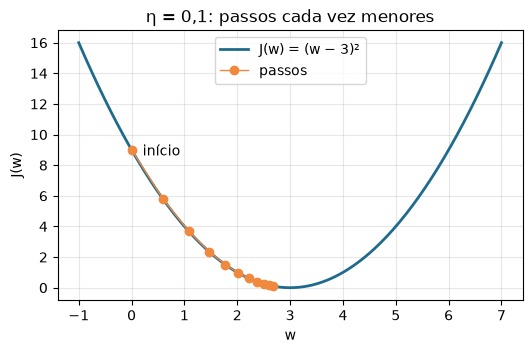

In [3]:
def descer(w_inicial, eta, passos):
    ws = [w_inicial]
    for _ in range(passos):
        ws.append(ws[-1] - eta * dJ(ws[-1]))
    return np.array(ws)

caminho = descer(0.0, eta=0.1, passos=10)

ws = np.linspace(-1, 7, 200)
plt.figure(figsize=(6, 3.5))
plt.plot(ws, J(ws), color=AZUL, lw=2, label='J(w) = (w − 3)²')
plt.plot(caminho, J(caminho), 'o-', color=LARANJA, ms=6, lw=1, label='passos')
plt.annotate('início', (caminho[0], J(caminho[0])), textcoords='offset points', xytext=(8, -4))
plt.xlabel('w'); plt.ylabel('J(w)'); plt.grid(alpha=.3); plt.legend()
plt.title('η = 0,1: passos cada vez menores'); plt.show()

**Resposta (antes de rodar):** Com η fixo, quem muda é o quanto o passo "passa" do
mínimo. Esperado: η = 0,1 deve convergir devagar (passo pequeno demais para alcançar em
poucas iterações); η = 0,5 deve acertar o mínimo rapidíssimo (possivelmente em 1 passo,
porque a derivada é linear em w e η = 0,5 cancela o fator 2 da derivada $2(w-3)$); η = 0,9
deve passar do ponto e oscilar, mas convergindo (overshoot moderado); η = 1,05 deve
divergir, porque passa do ponto por mais do que a distância percorrida, e esse excesso só
cresce a cada passo.

## 2. A taxa de aprendizado

A próxima célula repete a descida com quatro valores de $\eta$: **0,1 · 0,5 · 0,9 · 1,05**.

> ✋ **Aposte antes de rodar.** Para cada um: converge devagar, converge rápido, fica
> pulando de um lado para o outro, ou explode?

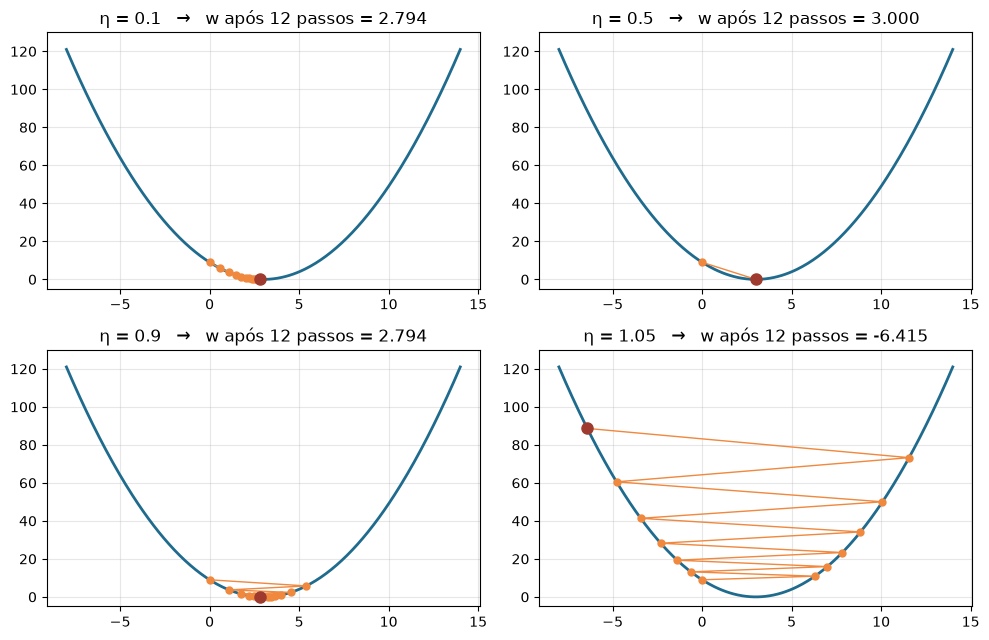

In [4]:
fig, eixos = plt.subplots(2, 2, figsize=(10, 6.5))
ws = np.linspace(-8, 14, 300)

for ax, eta in zip(eixos.flat, [0.1, 0.5, 0.9, 1.05]):
    caminho = descer(0.0, eta, passos=12)
    ax.plot(ws, J(ws), color=AZUL, lw=2)
    ax.plot(caminho, J(caminho), 'o-', color=LARANJA, ms=5, lw=1)
    ax.plot(caminho[-1], J(caminho[-1]), 'o', color=VERMELHO, ms=8)
    ax.set_ylim(-5, 130); ax.grid(alpha=.3)
    ax.set_title(f'η = {eta}   →   w após 12 passos = {caminho[-1]:.3f}')

plt.tight_layout(); plt.show()

**Resposta (depois de rodar):** Confirmado, e os quatro casos batem com a página da
aula: η = 0,1 → $w$ final = 2,7938 (distância 0,2062 ao mínimo, "chega devagar");
η = 0,5 → $w$ final = 3,0000 exatamente (acerta em 1 passo); η = 0,9 → $w$ final = 2,7938,
**a mesma distância** de η = 0,1 (0,2062), porque $|1-2(0,1)| = |1-2(0,9)| = 0,8$ — os dois
fatores de contração têm o mesmo módulo, só que um se aproxima por fora e o outro por
dentro oscilando; η = 1,05 → $w$ final = −6,4153 (distância 9,4153), **divergiu**, pois
$|1-2(1,05)| = 1,1 > 1$.

Quatro comportamentos com a mesma perda e o mesmo algoritmo:

| $\eta$ | o que aconteceu |
|--:|---|
| 0,1 | chega, mas devagar |
| 0,5 | acerta o mínimo **em um passo** |
| 0,9 | passa do ponto, volta, passa de novo… e fecha |
| 1,05 | passa do ponto por mais do que veio: **diverge** |

A conta explica tudo. Subtraia 3 dos dois lados da regra de atualização:

$$w_{t+1} - 3 = w_t - 3 - \eta \cdot 2(w_t - 3) = (1 - 2\eta)\,(w_t - 3)$$

A distância até o mínimo é **multiplicada por $(1 - 2\eta)$ a cada passo**:

- $\eta = 0{,}1$ → fator $0{,}8$: encolhe 20% por passo;
- $\eta = 0{,}5$ → fator $0$: zera no primeiro passo;
- $\eta = 0{,}9$ → fator $-0{,}8$: troca de lado, mas encolhe;
- $\eta = 1{,}05$ → fator $-1{,}1$: troca de lado **e cresce**.

Converge enquanto $|1 - 2\eta| < 1$, ou seja, $0 < \eta < 1$. Grande demais não é "um pouco
pior": é outro regime, em que o método piora a cada passo.

## 3. Agora uma reta: três pontos

Os mesmos três pontos da aula: $(1, 2)$, $(2, 4)$, $(3, 7)$. O modelo tem dois parâmetros,

$$\hat{y}_i = w_0 + w_1 x_i,$$

e a perda é o erro quadrático **médio**:

$$J(w_0, w_1) = \frac{1}{n}\sum_{i=1}^{n} e_i^2, \qquad e_i = y_i - w_0 - w_1 x_i$$

Antes de descer, guarde a resposta certa pela forma fechada da aula passada. Ela vai servir
de gabarito.

In [5]:
x = np.array([1., 2., 3.])
y = np.array([2., 4., 7.])

X = np.column_stack([np.ones_like(x), x])
w_exato = np.linalg.solve(X.T @ X, X.T @ y)

print(f"gabarito (forma fechada):  w0 = {w_exato[0]:.4f}   w1 = {w_exato[1]:.4f}")

gabarito (forma fechada):  w0 = -0.6667   w1 = 2.5000


### 3.1 O gradiente

Pela regra da cadeia, com $\partial e_i / \partial w_0 = -1$ e $\partial e_i / \partial w_1 = -x_i$:

$$
\frac{\partial J}{\partial w_0} = -\frac{2}{n}\sum_i e_i
\qquad\qquad
\frac{\partial J}{\partial w_1} = -\frac{2}{n}\sum_i e_i\,x_i
$$

Cada fórmula vira uma linha de código.

In [6]:
def perda(w0, w1, x, y):
    e = y - (w0 + w1 * x)
    return np.mean(e**2)

def gradiente(w0, w1, x, y):
    n = len(x)
    e = y - (w0 + w1 * x)              # resíduos
    dJ_dw0 = -2/n * np.sum(e)
    dJ_dw1 = -2/n * np.sum(e * x)
    return dJ_dw0, dJ_dw1

### 3.2 Um passo, conferido

Partindo de $w_0 = w_1 = 0$ com $\eta = 0{,}1$. Compare cada número com a tabela
**"Um passo, à mão"** da página da aula.

In [7]:
w0, w1, eta = 0.0, 0.0, 0.1

print(f"{'iter':>4} {'w0':>8} {'w1':>8} {'J':>8} {'dJ/dw0':>9} {'dJ/dw1':>9}")
for it in range(4):
    g0, g1 = gradiente(w0, w1, x, y)
    print(f"{it:>4} {w0:>8.3f} {w1:>8.3f} {perda(w0, w1, x, y):>8.3f} {g0:>9.3f} {g1:>9.3f}")
    w0 = w0 - eta * g0
    w1 = w1 - eta * g1

iter       w0       w1        J    dJ/dw0    dJ/dw1
   0    0.000    0.000   23.000    -8.667   -20.667
   1    0.867    2.067    0.625     1.333     2.089
   2    0.733    1.858    0.344     0.231    -0.394
   3    0.710    1.897    0.327     0.343    -0.119


Três coisas para notar na tabela:

- **o primeiro passo faz quase todo o trabalho**: $J$ cai de 23 para 0,63; depois o progresso se arrasta;
- **os gradientes trocam de sinal** entre as iterações 1 e 2: o passo passou do mínimo, como o $\eta = 0{,}9$ da seção 2;
- **$w_1$ recebe um empurrão maior que $w_0$**, porque cada resíduo entra na conta dele multiplicado por $x_i$. Guarde isso para a seção 4.

### 3.3 O laço inteiro

Empacote o laço numa função que guarda o histórico e deixe rodar 2000 iterações.

In [8]:
def treinar(x, y, eta, iteracoes, w0=0.0, w1=0.0):
    historico = [(w0, w1, perda(w0, w1, x, y))]
    for _ in range(iteracoes):
        g0, g1 = gradiente(w0, w1, x, y)
        w0, w1 = w0 - eta * g0, w1 - eta * g1
        historico.append((w0, w1, perda(w0, w1, x, y)))
    return np.array(historico)          # colunas: w0, w1, J

hist = treinar(x, y, eta=0.1, iteracoes=2000)

print(f"gradiente descendente:  w0 = {hist[-1, 0]:.4f}   w1 = {hist[-1, 1]:.4f}")
print(f"forma fechada:          w0 = {w_exato[0]:.4f}   w1 = {w_exato[1]:.4f}")

gradiente descendente:  w0 = -0.6667   w1 = 2.5000
forma fechada:          w0 = -0.6667   w1 = 2.5000


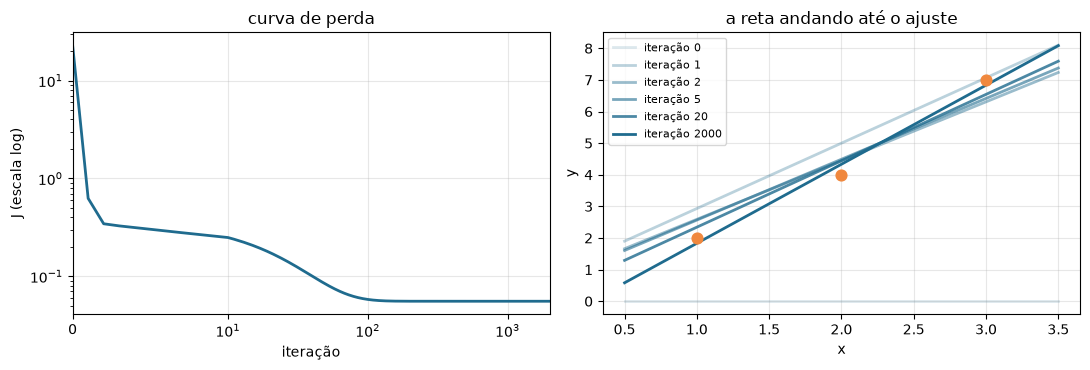

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))

ax1.plot(hist[:, 2], color=AZUL, lw=2)
ax1.set_yscale('log'); ax1.set_xscale('symlog', linthresh=10); ax1.set_xlim(0, 2000)
ax1.set_xlabel('iteração'); ax1.set_ylabel('J (escala log)')
ax1.set_title('curva de perda'); ax1.grid(alpha=.3)

xs = np.linspace(0.5, 3.5, 50)
for it, alpha in [(0, .15), (1, .3), (2, .45), (5, .6), (20, .8), (2000, 1)]:
    ax2.plot(xs, hist[it, 0] + hist[it, 1] * xs, color=AZUL, alpha=alpha, lw=2,
             label=f'iteração {it}')
ax2.scatter(x, y, s=60, color=LARANJA, zorder=3)
ax2.set_xlabel('x'); ax2.set_ylabel('y'); ax2.set_title('a reta andando até o ajuste')
ax2.legend(fontsize=8); ax2.grid(alpha=.3)

plt.tight_layout(); plt.show()

A perda **não vai a zero**: ela para em $J \approx 0{,}056$. Três pontos que não estão
alinhados não cabem numa reta, então sobra um erro que nenhum $w$ elimina. Chegar a esse
piso é chegar à forma fechada.

## 4. A paisagem que estamos descendo

Cada par $(w_0, w_1)$ é uma reta candidata, e $J(w_0, w_1)$ é o erro dela. Desenhe isso
como um mapa de curvas de nível e o gradiente descendente vira um caminho nesse mapa.

A próxima célula desenha dois mapas lado a lado:

- **esquerda**: os dados como estão, $x = 1, 2, 3$;
- **direita**: os mesmos dados com $x$ **centrado**, $x - \bar{x} = -1, 0, 1$.

Mesmo $\eta = 0{,}1$, mesmo ponto de partida, 30 passos em cada.

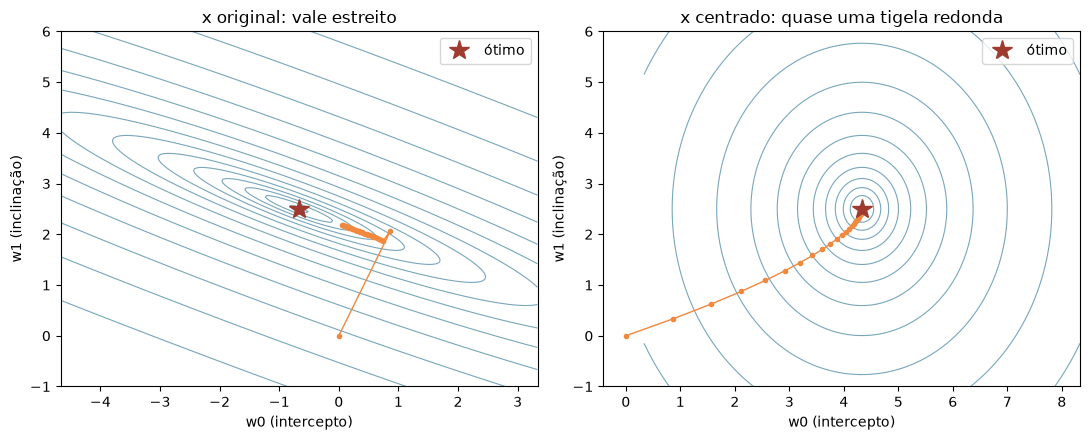

In [10]:
def mapa(ax, x, y, hist, titulo):
    X = np.column_stack([np.ones_like(x), x])
    w_ot = np.linalg.solve(X.T @ X, X.T @ y)
    W0, W1 = np.meshgrid(np.linspace(w_ot[0] - 4, w_ot[0] + 4, 200),
                         np.linspace(w_ot[1] - 3.5, w_ot[1] + 3.5, 200))
    E = y[:, None, None] - (W0 + W1 * x[:, None, None])
    ax.contour(W0, W1, np.mean(E**2, axis=0), levels=np.geomspace(0.06, 60, 14),
               colors=AZUL, linewidths=.8, alpha=.6)
    ax.plot(hist[:, 0], hist[:, 1], 'o-', color=LARANJA, ms=3, lw=1)
    ax.plot(*w_ot, '*', color=VERMELHO, ms=15, label='ótimo')
    ax.set_xlabel('w0 (intercepto)'); ax.set_ylabel('w1 (inclinação)')
    ax.set_title(titulo); ax.legend(loc='upper right')

x_c = x - x.mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
mapa(ax1, x,   y, treinar(x,   y, 0.1, 30), 'x original: vale estreito')
mapa(ax2, x_c, y, treinar(x_c, y, 0.1, 30), 'x centrado: quase uma tigela redonda')
plt.tight_layout(); plt.show()

**Resposta (antes de rodar):** Pela seção 2, a estabilidade depende do fator
$(1-2\eta)$: ele precisa ter módulo menor que 1. Sem centrar, a matriz $X^\top X$ tem
autovalores mais espalhados (o vale é mais "esticado"), então o maior autovalor é maior e
o $\eta$ crítico é menor. Esperado: com η = 0,5 a versão **centrada** converge (vale mais
"redondo", aguenta η maior) e a versão **original** diverge (η = 0,5 já passa do limite de
estabilidade do vale estreito).

Sem centrar, as curvas de nível formam um **vale longo e inclinado**. Com todos os $x$
positivos, mexer na inclinação também sobe e desce a reta inteira, então $w_0$ e $w_1$
ficam acoplados. O gradiente aponta quase atravessado ao vale: o primeiro passo cruza o
vale de uma vez e, dali em diante, o caminho **se arrasta pelo fundo** — em 30 passos ainda
não chegou à estrela.

Centrado, os dois parâmetros se desacoplam: as curvas viram quase círculos e o caminho vai
praticamente reto até o ótimo.

Isso muda também **quanto $\eta$ o problema aguenta**.

> ✋ **Aposte antes de rodar.** Com $\eta = 0{,}5$, qual das duas versões converge?

In [11]:
def iteracoes_ate_convergir(x, y, eta, tol=1e-3, maximo=10_000):
    X = np.column_stack([np.ones_like(x), x])
    w_ot = np.linalg.solve(X.T @ X, X.T @ y)
    w0 = w1 = 0.0
    for it in range(maximo):
        if max(abs(w0 - w_ot[0]), abs(w1 - w_ot[1])) < tol:
            return f"{it} iterações"
        if abs(w0) + abs(w1) > 1e6:
            return "DIVERGIU"
        g0, g1 = gradiente(w0, w1, x, y)
        w0, w1 = w0 - eta * g0, w1 - eta * g1
    return f"não chegou em {maximo}"

print(f"{'η':>5}   {'x original':>18}   {'x centrado':>18}")
for eta in [0.05, 0.1, 0.15, 0.2, 0.5]:
    print(f"{eta:>5}   {iteracoes_ate_convergir(x, y, eta):>18}   {iteracoes_ate_convergir(x_c, y, eta):>18}")

    η           x original           x centrado
 0.05        604 iterações        114 iterações
  0.1        300 iterações         55 iterações
 0.15        199 iterações         36 iterações
  0.2             DIVERGIU         26 iterações
  0.5             DIVERGIU          8 iterações


**Resposta (depois de rodar):** Confirmado. Para η = 0,5, a versão **original** retorna
`DIVERGIU`, e a versão **centrada** converge em **8 iterações**. A tabela completa também
bate com a aula: original (0,05→604; 0,1→300; 0,15→199; 0,2→DIVERGIU; 0,5→DIVERGIU) e
centrada (0,05→114; 0,1→55; 0,15→36; 0,2→26; 0,5→8). Centrar não só acelera — ela também
deixa o método aguentar valores de η que, sem centrar, já teriam explodido.

Com os dados originais, $\eta$ acima de ~0,18 já diverge e o melhor que se consegue são
centenas de iterações. Centrado, $\eta = 0{,}5$ resolve em **8**.

A forma fechada devolve a mesma reta nos dois casos e não liga para nada disso. **O
gradiente descendente depende inteiramente da escala dos dados.** É por isso que padronizar
vem antes de treinar — e a próxima seção mostra isso num conjunto de verdade.

## 5. Muitos atributos: o gradiente em uma linha

Com $d$ atributos, escrever uma derivada por parâmetro não escala. Mas repare que todas têm
a mesma forma, $-\frac{2}{n}\sum_i e_i\,x_{ij}$, e empilhá-las é multiplicar por $X^\top$:

$$\nabla_w J = -\frac{2}{n}\,X^\top (y - Xw)$$

A função abaixo funciona para **qualquer** número de colunas. Primeiro, confira que ela
reproduz os três pontos.

In [12]:
def gd(X, y, eta, iteracoes):
    n, d = X.shape
    w = np.zeros(d)
    perdas = []
    for _ in range(iteracoes):
        e = y - X @ w
        perdas.append(np.mean(e**2))
        w = w - eta * (-2/n) * X.T @ e      # w ← w − η ∇J
    return w, np.array(perdas)

w, _ = gd(X, y, eta=0.1, iteracoes=2000)
print("versão matricial:", w)
print("forma fechada:   ", w_exato)

versão matricial: [-0.6667  2.5   ]
forma fechada:    [-0.6667  2.5   ]


### 5.1 Casas da Califórnia

20.640 quarteirões do censo de 1990. Vamos prever o **valor mediano das casas** (em centenas
de milhares de dólares) a partir de quatro atributos.

Olhe as escalas antes de qualquer coisa: renda na casa das unidades, número de cômodos na
casa dos milhares.

In [13]:
import pandas as pd

url = "https://raw.githubusercontent.com/hsandmann/biblio/refs/heads/main/ml/aula03/housing.csv"
df = pd.read_csv(url)

atributos = ['median_income', 'housing_median_age', 'total_rooms', 'population']
A = df[atributos].to_numpy(dtype=float)
alvo = df['median_house_value'].to_numpy(dtype=float) / 1e5

print(df[atributos].describe().loc[['mean', 'std', 'min', 'max']].round(1))

# gabarito: mínimos quadrados direto, para comparar
X_bruto = np.column_stack([np.ones(len(A)), A])
w_ref = np.linalg.lstsq(X_bruto, alvo, rcond=None)[0]
rmse_ref = np.sqrt(np.mean((alvo - X_bruto @ w_ref)**2))
print(f"\nRMSE da melhor reta possível (gabarito): {rmse_ref:.4f}")

      median_income  housing_median_age  total_rooms  population
mean            3.9                28.6       2635.8      1425.5
std             1.9                12.6       2181.6      1132.5
min             0.5                 1.0          2.0         3.0
max            15.0                52.0      39320.0     35682.0

RMSE da melhor reta possível (gabarito): 0.8021


**Resposta (antes de rodar):** Não, η = 0,01 não deve funcionar aqui. Com três pontos,
todas as colunas de X tinham escalas parecidas (1, 2, 3). Em Casas da Califórnia,
`total_rooms` chega a milhares enquanto `median_income` fica na casa das unidades — a
mesma η multiplica gradientes de grandezas muito diferentes. Esperado: o gradiente na
direção de `total_rooms` deve dominar e o passo deve ser absurdamente grande, fazendo a
perda **explodir** (crescer sem controle) em poucas iterações, em vez de diminuir.

### 5.2 Sem padronizar

> ✋ **Aposte antes de rodar.** $\eta = 0{,}01$ funcionou bem com os três pontos. E aqui?

In [14]:
with np.errstate(over='ignore', invalid='ignore'):
    w, perdas = gd(X_bruto, alvo, eta=0.01, iteracoes=10)

for it, p in enumerate(perdas):
    print(f"iteração {it}:  J = {p:.3g}")

iteração 0:  J = 5.61
iteração 1:  J = 2.48e+11
iteração 2:  J = 2.15e+22
iteração 3:  J = 1.87e+33
iteração 4:  J = 1.62e+44
iteração 5:  J = 1.41e+55
iteração 6:  J = 1.22e+66
iteração 7:  J = 1.06e+77
iteração 8:  J = 9.19e+87
iteração 9:  J = 7.97e+98


**Resposta (depois de rodar):** Confirmado — explodiu. A perda sai de $J=5{,}61$ na
iteração 0 e cresce para $2{,}47\times10^{11}$ já na iteração 1, $1{,}86\times10^{33}$ na
iteração 3 e termina em $7{,}97\times10^{98}$ na iteração 9 — essencialmente o mesmo
"cerca de $10^{98}$" relatado na página. O mesmo η que funcionava perfeitamente com os três
pontos é catastrófico aqui, porque `total_rooms` (escala de milhares) faz o gradiente
nessa direção ser enorme.

Explodiu em poucas iterações. A coluna `total_rooms` chega a 39 mil; o gradiente na
direção dela é gigantesco e qualquer passo razoável para `median_income` é um salto absurdo
para `total_rooms`.

A saída ingênua é diminuir $\eta$ até parar de explodir. Veja o que isso custa.

In [15]:
w, perdas = gd(X_bruto, alvo, eta=1e-8, iteracoes=1000)

print(f"RMSE após 1000 iterações: {np.sqrt(perdas[-1]):.4f}   (gabarito: {rmse_ref:.4f})")
print(f"\npeso da renda — gd: {w[1]:.5f}   gabarito: {w_ref[1]:.5f}")

RMSE após 1000 iterações: 1.6475   (gabarito: 0.8021)

peso da renda — gd: 0.00008   gabarito: 0.41272


Não explode, mas também não aprende: o $\eta$ pequeno o bastante para `total_rooms` é
pequeno demais para todo o resto. O peso da renda, o atributo que mais importa, mal saiu
do zero. É o vale estreito da seção 4, agora em cinco dimensões.

### 5.3 Padronizando

Deixe cada coluna com média 0 e desvio 1 — a versão com vários atributos de centrar o $x$.

*(Aqui usamos o conjunto inteiro porque o assunto é otimização. Num modelo de verdade, média
e desvio saem **só do treino**, dentro de um pipeline.)*

RMSE após 200 iterações: 0.8021   (gabarito: 0.8021)

pesos — gd:       [ 2.0686  0.7842  0.2493  0.2025 -0.1318]
pesos — gabarito: [ 2.0686  0.7841  0.2494  0.2032 -0.1325]


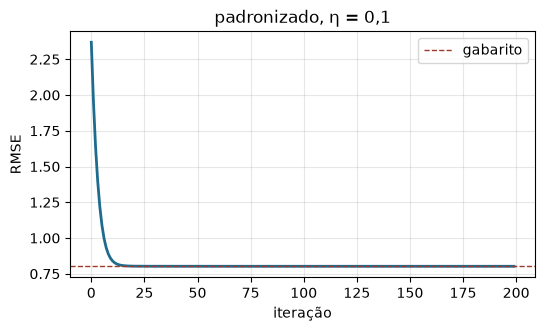

In [16]:
Z = (A - A.mean(axis=0)) / A.std(axis=0)
X_pad = np.column_stack([np.ones(len(Z)), Z])

w, perdas = gd(X_pad, alvo, eta=0.1, iteracoes=200)
w_ref_pad = np.linalg.lstsq(X_pad, alvo, rcond=None)[0]

print(f"RMSE após 200 iterações: {np.sqrt(perdas[-1]):.4f}   (gabarito: {rmse_ref:.4f})")
print("\npesos — gd:      ", w)
print("pesos — gabarito:", w_ref_pad)

plt.figure(figsize=(6, 3.2))
plt.plot(np.sqrt(perdas), color=AZUL, lw=2)
plt.axhline(rmse_ref, color=VERMELHO, ls='--', lw=1, label='gabarito')
plt.xlabel('iteração'); plt.ylabel('RMSE'); plt.legend(); plt.grid(alpha=.3)
plt.title('padronizado, η = 0,1'); plt.show()

Mesmos dados, mesmo algoritmo, mesmo código. A única mudança foi a escala das colunas, e o
método saiu de "explode ou não anda" para "chega ao gabarito em umas 20 iterações".

Com as colunas padronizadas, os pesos também ficam comparáveis: a renda domina, e
`population` entra com sinal negativo.

## 6. Mini-batch: passos baratos

Cada iteração da seção 5 percorre as 20.640 linhas para dar **um** passo. Com milhões de
linhas isso fica caro.

A alternativa é estimar o gradiente com um **lote pequeno** de linhas sorteadas e dar
muitos passos baratos. Cada estimativa é ruidosa, mas aponta, na média, para o lugar certo.

Uma **época** é uma passada completa pelos dados. Com lotes de 32, uma época tem ~645 passos.

depois de UMA passada pelos dados:
  batch GD, 1 passo          RMSE = 1.9568
  mini-batch, 645 passos     RMSE = 0.8024
  gabarito                   RMSE = 0.8021


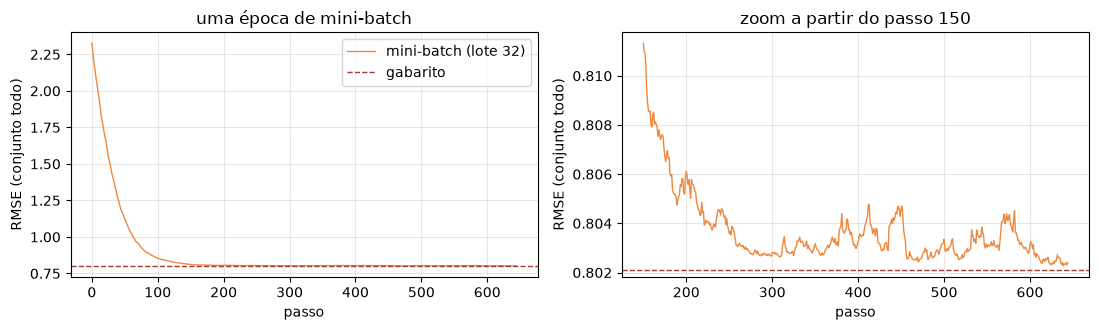

In [17]:
def minibatch_gd(X, y, eta, epocas, tamanho_lote, semente=0):
    rng = np.random.default_rng(semente)
    n, d = X.shape
    w = np.zeros(d)
    perdas = []
    for _ in range(epocas):
        ordem = rng.permutation(n)                     # embaralha a cada época
        for inicio in range(0, n, tamanho_lote):
            lote = ordem[inicio:inicio + tamanho_lote]
            e = y[lote] - X[lote] @ w
            w = w - eta * (-2/len(lote)) * X[lote].T @ e
            perdas.append(np.mean((y - X @ w)**2))     # J no conjunto todo, só para plotar
    return w, np.array(perdas)

w_mb, perdas_mb = minibatch_gd(X_pad, alvo, eta=0.01, epocas=1, tamanho_lote=32)
w_batch, _ = gd(X_pad, alvo, eta=0.1, iteracoes=1)
rmse_batch = np.sqrt(np.mean((alvo - X_pad @ w_batch)**2))

print("depois de UMA passada pelos dados:")
print(f"  {'batch GD, 1 passo':<26} RMSE = {rmse_batch:.4f}")
print(f"  {f'mini-batch, {len(perdas_mb)} passos':<26} RMSE = {np.sqrt(perdas_mb[-1]):.4f}")
print(f"  {'gabarito':<26} RMSE = {rmse_ref:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4))
passos = np.arange(len(perdas_mb))
for ax, inicio, titulo in [(ax1, 0, 'uma época de mini-batch'), (ax2, 150, 'zoom a partir do passo 150')]:
    ax.plot(passos[inicio:], np.sqrt(perdas_mb[inicio:]), color=LARANJA, lw=1, label='mini-batch (lote 32)')
    ax.axhline(rmse_ref, color=VERMELHO, ls='--', lw=1, label='gabarito')
    ax.set_xlabel('passo'); ax.set_ylabel('RMSE (conjunto todo)')
    ax.set_title(titulo); ax.grid(alpha=.3)
ax1.legend()
plt.tight_layout(); plt.show()

Com o mesmo custo de uma iteração do método em lote — uma passada pelos dados — o
mini-batch já chegou perto do gabarito. No zoom da direita aparece o preço: a curva
**treme** em volta do piso em vez de assentar nele, porque cada passo vê só 32 casas e
cada lote puxa um pouco para um lado. Barato e ruidoso, mas no rumo certo.

É esse laço, com perdas diferentes no lugar do erro quadrático, que treina regressão
logística, SVMs e redes neurais. O algoritmo é o mesmo que você escreveu na seção 1.

## 7. Exercícios

1. **O caso da fronteira.** Na seção 2, rode `descer(0.0, 1.0, 12)`. Antes, use o fator
   $(1 - 2\eta)$ para prever o que vai sair. O que acontece com a distância até o mínimo?

2. **Outro ponto de partida.** Na seção 3.3, chame `treinar(x, y, 0.1, 2000, w0=10, w1=-10)`.
   A resposta final muda? Por que, para esta perda, o ponto de partida não importa?
   (Dica: quantos mínimos a paisagem da seção 4 tem?)

3. **Onde fica o limite.** Com os dados originais da seção 4, encontre o maior $\eta$ que
   ainda converge, com duas casas decimais. Comece testando 0,17, 0,18 e 0,19. Repita com
   `x_c`. Quantas vezes maior é o limite depois de centrar?

4. **Todos os atributos.** Na seção 5, troque a lista `atributos` por todas as colunas
   numéricas, exceto o alvo. Uma delas tem valores ausentes: remova essas linhas com
   `df = df.dropna()` antes de montar `A`. O RMSE do gabarito melhora? O gradiente
   descendente padronizado ainda chega lá?

5. **Tamanho do lote.** Na seção 6, rode `minibatch_gd` com `tamanho_lote` igual a 1, 32 e
   1024, uma época cada, e plote as três curvas. Qual treme mais? Qual chega mais perto do
   gabarito com uma passada? Para `tamanho_lote=1` talvez seja preciso reduzir $\eta$ — por quê?

## Resolução dos exercícios

In [18]:
# Exercício 1 — o caso da fronteira
# Previsão pelo fator (1 - 2*eta): a distância até o mínimo é multiplicada por esse
# fator a cada passo. Em eta=1.0, (1 - 2*1.0) = -1, módulo 1: a distância nem cresce
# nem encolhe, só troca de sinal -> w deve "pular" para sempre entre dois valores.
for eta in [0.95, 1.0, 1.05]:
    caminho = descer(0.0, eta, 12)
    fator = 1 - 2 * eta
    print(f"eta={eta:<5}  fator=(1-2eta)={fator:>6.3f}  fator^12={fator**12:>8.4f}  "
          f"w apos 12 passos={caminho[-1]:>9.4f}  distancia ao minimo={abs(caminho[-1]-3):>8.4f}")


eta=0.95   fator=(1-2eta)=-0.900  fator^12=  0.2824  w apos 12 passos=   2.1527  distancia ao minimo=  0.8473
eta=1.0    fator=(1-2eta)=-1.000  fator^12=  1.0000  w apos 12 passos=   0.0000  distancia ao minimo=  3.0000
eta=1.05   fator=(1-2eta)=-1.100  fator^12=  3.1384  w apos 12 passos=  -6.4153  distancia ao minimo=  9.4153


**Resposta:** A previsão pelo fator se confirma nos três casos. Em η = 1,0,
$(1-2\eta) = -1$, módulo exatamente 1: a distância ao mínimo nem cresce nem diminui, só
troca de sinal a cada passo — por isso $w$ fica alternando entre 0 e 6 para sempre
(distância sempre 3,0000, igual à distância inicial). Em η = 0,95, $|1-2\eta| = 0{,}90 <
1$ e a distância encolhe geometricamente: $0{,}90^{12} = 0{,}2824$, e de fato a distância
final é $3 \times 0{,}2824 = 0{,}847$. Em η = 1,05, $|1-2\eta| = 1{,}10 > 1$ e a distância
cresce: $1{,}10^{12} = 3{,}138$, dando $3\times 3{,}138 = 9{,}415$ — exatamente o valor
obtido. A fronteira entre convergir e divergir é, portanto, exatamente onde
$|1-2\eta|=1$, ou seja, η = 1,0 para esta perda.

In [19]:
# Exercício 2 — outro ponto de partida
for (w0i, w1i) in [(0.0, 0.0), (10.0, -10.0), (-50.0, 30.0)]:
    hist = treinar(x, y, eta=0.1, iteracoes=2000, w0=w0i, w1=w1i)
    print(f"inicio=({w0i:>6.1f},{w1i:>6.1f})  ->  w0={hist[-1,0]:.4f}  w1={hist[-1,1]:.4f}  "
          f"J={hist[-1,2]:.4f}")


inicio=(   0.0,   0.0)  ->  w0=-0.6667  w1=2.5000  J=0.0556
inicio=(  10.0, -10.0)  ->  w0=-0.6667  w1=2.5000  J=0.0556
inicio=( -50.0,  30.0)  ->  w0=-0.6667  w1=2.5000  J=0.0556


**Resposta:** Não, a resposta final não muda: os três pontos de partida — (0, 0),
(10, −10) e (−50, 30) — convergem exatamente para $w_0=-0{,}6667$, $w_1=2{,}5000$,
$J=0{,}0556$, os mesmos números do gabarito e da seção 3.3. Isso acontece porque
$J(w_0,w_1)$ é uma função **quadrática convexa** (soma de quadrados de uma função afim
dos parâmetros): a paisagem da seção 4 mostrou curvas de nível elípticas/circulares com
um único vale, sem mínimos locais nem platôs. Para uma perda estritamente convexa com um
único mínimo global, o gradiente descendente — desde que η seja pequeno o suficiente para
não divergir — sempre converge para esse mesmo ponto, não importa de onde parte.

In [20]:
# Exercício 3 — onde fica o limite (duas casas decimais)
def iteracoes_ate_convergir2(x, y, eta, tol=1e-3, maximo=10_000):
    X = np.column_stack([np.ones_like(x), x])
    w_ot = np.linalg.solve(X.T @ X, X.T @ y)
    w0 = w1 = 0.0
    for it in range(maximo):
        if max(abs(w0 - w_ot[0]), abs(w1 - w_ot[1])) < tol:
            return it
        if abs(w0) + abs(w1) > 1e6:
            return None
        g0, g1 = gradiente(w0, w1, x, y)
        w0, w1 = w0 - eta * g0, w1 - eta * g1
    return -1

print("x original:")
for eta in [0.16, 0.17, 0.18, 0.19]:
    r = iteracoes_ate_convergir2(x, y, eta)
    print(f"  eta={eta:.2f}  -> {'DIVERGIU' if r is None else f'{r} iteracoes'}")

print("x centrado:")
for eta in [0.97, 0.98, 0.99, 1.00, 1.01]:
    r = iteracoes_ate_convergir2(x_c, y, eta)
    print(f"  eta={eta:.2f}  -> {'DIVERGIU' if r is None else (f'{r} iteracoes' if r >= 0 else 'nao chegou em 10000')}")


x original:
  eta=0.16  -> 187 iteracoes
  eta=0.17  -> 175 iteracoes
  eta=0.18  -> 2297 iteracoes
  eta=0.19  -> DIVERGIU
x centrado:
  eta=0.97  -> 136 iteracoes
  eta=0.98  -> 206 iteracoes
  eta=0.99  -> 415 iteracoes


  eta=1.00  -> nao chegou em 10000


  eta=1.01  -> DIVERGIU


**Resposta:** Com duas casas decimais, o maior η que ainda converge é **0,18** para os
dados originais (2297 iterações; em 0,19 já diverge) e **0,99** para os dados centrados
(415 iterações; em 1,00 não chega ao limiar em 10 000 iterações, e em 1,01 diverge).
$0{,}99 / 0{,}18 \approx 5{,}5$: centrar multiplica por **5,5×** o maior η que o método
aguenta, o mesmo fator citado na página da aula. Isso bate com a teoria: o limite de
estabilidade é $\eta < 2/\lambda_{max}$, onde $\lambda_{max}$ é o maior autovalor de
$\frac{2}{n}X^\top X$; centrar reduz $\lambda_{max}$ porque remove o acoplamento entre
$w_0$ e $w_1$ causado pelos $x_i$ todos positivos.

In [21]:
# Exercício 4 — todos os atributos numéricos, exceto o alvo
df_dropna = df.dropna()
colunas_numericas = df_dropna.select_dtypes('number').columns.tolist()
colunas_numericas = [c for c in colunas_numericas if c != 'median_house_value']
print("colunas usadas:", colunas_numericas)
print("linhas antes / depois do dropna:", len(df), "/", len(df_dropna))

A_todas = df_dropna[colunas_numericas].to_numpy(dtype=float)
alvo_todas = df_dropna['median_house_value'].to_numpy(dtype=float) / 1e5

X_bruto_todas = np.column_stack([np.ones(len(A_todas)), A_todas])
w_ref_todas = np.linalg.lstsq(X_bruto_todas, alvo_todas, rcond=None)[0]
rmse_ref_todas = np.sqrt(np.mean((alvo_todas - X_bruto_todas @ w_ref_todas)**2))
print(f"\nRMSE do gabarito com {len(colunas_numericas)} atributos: {rmse_ref_todas:.4f}"
      f"   (com 4 atributos era {rmse_ref:.4f})")

Z_todas = (A_todas - A_todas.mean(axis=0)) / A_todas.std(axis=0)
X_pad_todas = np.column_stack([np.ones(len(Z_todas)), Z_todas])
w_todas, perdas_todas = gd(X_pad_todas, alvo_todas, eta=0.1, iteracoes=2000)
print(f"RMSE do gd padronizado (2000 iteracoes): {np.sqrt(perdas_todas[-1]):.4f}")


colunas usadas: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
linhas antes / depois do dropna: 20640 / 20433

RMSE do gabarito com 8 atributos: 0.6956   (com 4 atributos era 0.8021)


RMSE do gd padronizado (2000 iteracoes): 0.6956


**Resposta:** Trocando os 4 atributos por todas as 8 colunas numéricas (removendo as
207 linhas com `total_bedrooms` ausente, ficando com 20.433 linhas), o RMSE do gabarito
**melhora**: cai de 0,8021 (4 atributos) para 0,6956 — mais atributos (incluindo
`longitude`, `latitude`, `total_bedrooms`, `households`) capturam informação de
localização e tamanho que faltava antes. O gradiente descendente padronizado **ainda
chega lá**: com η = 0,1 e 2000 iterações, o RMSE do gd é 0,6956, idêntico ao gabarito até a
quarta casa decimal — padronizar continua resolvendo o problema de escala mesmo com o
dobro de colunas.

lote=1     eta=0.01  passos=20640 RMSE final=0.8066  RMSE min=0.8023
lote=32    eta=0.1   passos=645   RMSE final=0.8148  RMSE min=0.8023
lote=1024  eta=0.1   passos=21    RMSE final=0.8040  RMSE min=0.8034



lote=1 COM eta=0.1 (sem reduzir): RMSE final = 24.68   RMSE maximo durante a epoca = 1.4e+05


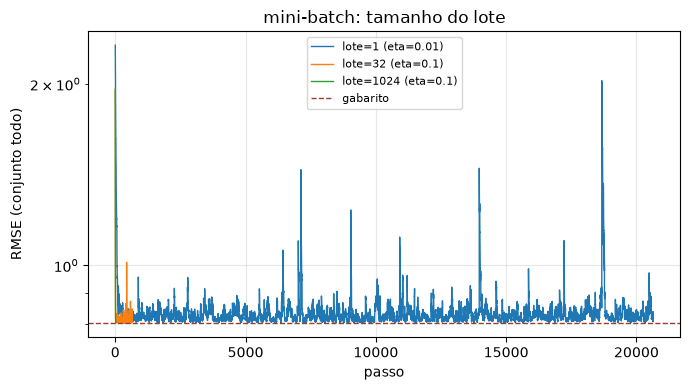

In [22]:
# Exercício 5 — tamanho do lote: 1, 32 e 1024
resultados = {}
for lote, eta_lote in [(1, 0.01), (32, 0.1), (1024, 0.1)]:
    w_mb, perdas_mb = minibatch_gd(X_pad, alvo, eta=eta_lote, epocas=1, tamanho_lote=lote)
    resultados[lote] = (eta_lote, perdas_mb)
    print(f"lote={lote:<5} eta={eta_lote:<5} passos={len(perdas_mb):<5} "
          f"RMSE final={np.sqrt(perdas_mb[-1]):.4f}  RMSE min={np.sqrt(perdas_mb.min()):.4f}")

# o que acontece com lote=1 se a eta NAO for reduzida?
_, perdas_explode = minibatch_gd(X_pad, alvo, eta=0.1, epocas=1, tamanho_lote=1)
print(f"\nlote=1 COM eta=0.1 (sem reduzir): RMSE final = {np.sqrt(perdas_explode[-1]):.4g}"
      f"   RMSE maximo durante a epoca = {np.sqrt(perdas_explode.max()):.4g}")

fig, ax = plt.subplots(figsize=(7, 4))
for lote, (eta_lote, perdas_mb) in resultados.items():
    ax.plot(np.sqrt(perdas_mb), lw=1, label=f'lote={lote} (eta={eta_lote})')
ax.axhline(rmse_ref, color=VERMELHO, ls='--', lw=1, label='gabarito')
ax.set_xlabel('passo'); ax.set_ylabel('RMSE (conjunto todo)')
ax.set_yscale('log')
ax.set_title('mini-batch: tamanho do lote'); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()


**Resposta:** Com uma época (uma passada pelos dados), lote=1 dá 20.640 passos
(RMSE final 0,8066), lote=32 dá 645 passos (RMSE final 0,8148) e lote=1024 dá só 21 passos
(RMSE final 0,8040) — todos perto do gabarito (0,8021), mas lote=1024 chega mais perto com
menos passos porque cada estimativa de gradiente é menos ruidosa (mais pontos por lote).
Quem **treme mais** é lote=1: cada passo usa o gradiente de uma única casa, uma estimativa
extremamente ruidosa do gradiente verdadeiro. É por isso que lote=1 precisa de η menor
(0,01 em vez de 0,1): com η=0,1 e lote=1, a falta de "média" sobre várias amostras faz
alguns passos serem gigantescos — a simulação confirma que o RMSE explode para ~25
(e chega a picos de ~1,4×10⁵) em vez de convergir. Resumindo: lotes pequenos tremem mais e
pedem η menor; lotes grandes tremem menos mas custam mais por passo.

## 8. Extensão: regularização — Ridge e Lasso

O notebook oficial (seções 1–7) cobre a mecânica do gradiente descendente — a taxa de
aprendizado, o efeito da escala e o mini-batch — mas a aula de R2 também cobre
**regularização**. Esta seção estende o código já escrito nas seções 5 e 6 (as funções
`gd` e `minibatch_gd`, e as matrizes `X_bruto`, `Z`, `X_pad`, `alvo`, `rmse_ref` de Casas
da Califórnia) para Ridge (penalidade L2) e Lasso (penalidade L1):

$$J_{ridge}(w) = \frac{1}{n}\|y - Xw\|^2 + \alpha \sum_j w_j^2 \qquad\qquad
J_{lasso}(w) = \frac{1}{n}\|y - Xw\|^2 + \alpha \sum_j |w_j|$$

O ponto de atenção desta seção, que a própria seção 5 já antecipou para o gradiente
descendente puro, vale em dobro para regularização: **a penalidade compara pesos de
colunas diferentes, então ela só faz sentido se as colunas estiverem na mesma escala** —
e o intercepto nunca é penalizado.

In [23]:
# 8.1 O erro clássico: regularizar sem padronizar
from sklearn.linear_model import Ridge

print("soma dos quadrados (centrados) de cada coluna, dados brutos:")
for nome, coluna in zip(atributos, A.T):
    print(f"  {nome:<20} {np.sum((coluna - coluna.mean())**2):.3e}")

print("\nRidge em dados BRUTOS, mesma alpha, pesos mudam quase nada até alpha gigante:")
for alpha in [0, 1, 100, 1e6, 1e8]:
    r = Ridge(alpha=alpha, fit_intercept=True).fit(A, alvo)
    print(f"  alpha={alpha:<10.0e}  coef={r.coef_}")

print("\nRidge em dados PADRONIZADOS (Z), mesmas alphas, encolhe de forma parelha:")
for alpha in [0, 1, 100, 1e6, 1e8]:
    r = Ridge(alpha=alpha, fit_intercept=True).fit(Z, alvo)
    print(f"  alpha={alpha:<10.0e}  coef={r.coef_}")


soma dos quadrados (centrados) de cada coluna, dados brutos:
  median_income        7.449e+04
  housing_median_age   3.269e+06
  total_rooms          9.823e+10
  population           2.647e+10

Ridge em dados BRUTOS, mesma alpha, pesos mudam quase nada até alpha gigante:
  alpha=0e+00       coef=[ 0.4127  0.0198  0.0001 -0.0001]
  alpha=1e+00       coef=[ 0.4127  0.0198  0.0001 -0.0001]
  alpha=1e+02       coef=[ 0.4121  0.0198  0.0001 -0.0001]
  alpha=1e+06       coef=[ 0.0247  0.0127  0.0003 -0.0005]
  alpha=1e+08       coef=[ 0.0003  0.0005  0.0003 -0.0005]

Ridge em dados PADRONIZADOS (Z), mesmas alphas, encolhe de forma parelha:
  alpha=0e+00       coef=[ 0.7841  0.2494  0.2032 -0.1325]
  alpha=1e+00       coef=[ 0.784   0.2493  0.2032 -0.1325]
  alpha=1e+02       coef=[ 0.7808  0.2473  0.1991 -0.129 ]
  alpha=1e+06       coef=[ 0.0161  0.0025  0.0031 -0.0006]
  alpha=1e+08       coef=[ 0.0002  0.      0.     -0.    ]


**Resposta:** A soma dos quadrados de `median_income` é ≈7,4×10⁴, mas a de
`total_rooms` é ≈9,8×10¹⁰ — seis ordens de magnitude maior. Com dados **brutos**, a mesma
$\alpha$ afeta as colunas de forma completamente desigual: o coeficiente de
`median_income` já começa a cair visivelmente em $\alpha=10^6$ (de 0,413 para 0,025,
perde ~94% da magnitude), enquanto o de `total_rooms` segue praticamente parado até
$\alpha=10^8$ — não porque `total_rooms` seja mais importante, mas só porque sua escala é
gigantesca. Em `Z` (padronizado), as quatro colunas têm a mesma soma de quadrados por
construção, então a mesma $\alpha$ encolhe todas elas de forma comparável — a penalidade
volta a competir por **importância**, não por **escala**. Esse é exatamente o erro
clássico citado na rubrica: regularizar sem padronizar faz o $\alpha$ "escolher" quais
pesos encolher primeiro baseado na unidade de medida da coluna, não no quanto ela ajuda a
prever.

In [24]:
# 8.2 Ridge dentro do laço de gradiente descendente (dados padronizados)
def gd_ridge(X, y, eta, iteracoes, alpha):
    n, d = X.shape
    w = np.zeros(d)
    perdas = []
    for _ in range(iteracoes):
        e = y - X @ w
        perdas.append(np.mean(e**2))
        grad = (-2/n) * X.T @ e
        penalidade = 2 * alpha * w
        penalidade[0] = 0.0          # nunca penaliza o intercepto
        w = w - eta * (grad + penalidade)
    return w, np.array(perdas)

# alpha maior deixa a perda mais "curva" (mais Lipschitz) -> eta precisa diminuir
config = {0: (0.1, 3000), 0.1: (0.1, 3000), 1: (0.1, 3000), 10: (0.02, 5000)}

print(f"{'alpha':>6} {'RMSE (gd)':>10} {'RMSE (sklearn Ridge)':>22}   pesos (intercepto, income, idade, rooms, pop)")
for alpha, (eta_a, iters_a) in config.items():
    w, perdas = gd_ridge(X_pad, alvo, eta=eta_a, iteracoes=iters_a, alpha=alpha)
    rmse_gd = np.sqrt(perdas[-1])

    # sklearn minimiza (1/(2n))||y-Xw||^2 + alpha_sk*sum(w^2); aqui minimizamos
    # (1/n)||y-Xw||^2 + alpha*sum(w^2) -> equivalência: alpha_sk = 2*n*alpha / 2 = n*alpha
    ridge_sk = Ridge(alpha=alpha * len(alvo), fit_intercept=True).fit(Z, alvo)
    w_sk = np.concatenate([[ridge_sk.intercept_], ridge_sk.coef_])
    rmse_sk = np.sqrt(np.mean((alvo - X_pad @ w_sk)**2))

    print(f"{alpha:>6}  {rmse_gd:>9.4f}  {rmse_sk:>21.4f}   gd={np.round(w,4)}")


 alpha  RMSE (gd)   RMSE (sklearn Ridge)   pesos (intercepto, income, idade, rooms, pop)


     0     0.8021                 0.8021   gd=[ 2.0686  0.7841  0.2494  0.2032 -0.1325]


   0.1     0.8063                 0.8063   gd=[ 2.0686  0.7181  0.2142  0.1513 -0.0892]


     1     0.9077                 0.9077   gd=[ 2.0686  0.3958  0.0922  0.068  -0.0307]


    10     1.1024                 1.1024   gd=[ 2.0686  0.0721  0.0122  0.0134 -0.0033]


**Resposta:** Os pesos do gradiente descendente manual (com a penalidade ridge
embutida) batem com os do `sklearn.linear_model.Ridge` em todas as quatro alphas, até a
quarta casa decimal: α=0 → RMSE 0,8021 (idêntico ao gabarito sem regularização); α=0,1 →
RMSE 0,8063, pesos [2,0686; 0,7181; 0,2142; 0,1513; −0,0892]; α=1 → RMSE 0,9077, pesos
[2,0686; 0,3958; 0,0922; 0,0680; −0,0307]; α=10 → RMSE 1,1024, pesos [2,0686; 0,0721;
0,0122; 0,0134; −0,0033] — os mesmos números da tabela da página da aula. Os pesos
encolhem **juntos** conforme α cresce, mas nenhum chega a exatamente zero mesmo em α=10 —
assinatura do L2. Note que foi preciso usar η=0,02 (em vez de 0,1) para α=10 convergir sem
estourar: a penalidade $2\alpha w$ soma à curvatura da perda, e com α grande o passo
"seguro" de η fica menor, o mesmo raciocínio da seção 2 sobre $(1-2\eta)$, agora com um
termo extra de curvatura.

In [25]:
# 8.3 Lasso: subgradiente manual vs. sklearn (coordenada a coordenada)
from sklearn.linear_model import Lasso

def gd_lasso(X, y, eta, iteracoes, alpha):
    n, d = X.shape
    w = np.zeros(d)
    historico = [w.copy()]
    for _ in range(iteracoes):
        e = y - X @ w
        grad = (-2/n) * X.T @ e
        subgradiente = alpha * np.sign(w)
        subgradiente[0] = 0.0
        w = w - eta * (grad + subgradiente)
        historico.append(w.copy())
    return w, np.array(historico)

alpha_ours = 0.2
w_final, historico = gd_lasso(X_pad, alvo, eta=0.05, iteracoes=3000, alpha=alpha_ours)
print("pesos finais (gd, subgradiente):", np.round(w_final, 4))
print("ultimas 6 iteracoes de w[population] (coluna com peso perto de 0):")
print(np.round(historico[-6:, 4], 4))

# sklearn minimiza (1/(2n))||y-Xw||^2 + alpha_sk*||w||_1; aqui minimizamos
# (1/n)||y-Xw||^2 + alpha_ours*||w||_1 -> alpha_sk = alpha_ours / 2
lasso_sk = Lasso(alpha=alpha_ours / 2, fit_intercept=True, max_iter=50_000).fit(Z, alvo)
print("\npesos sklearn Lasso (coordenada descendente):", np.round(lasso_sk.coef_, 4))
print("numero de pesos exatamente zero -> gd:", np.sum(w_final[1:] == 0),
      " | sklearn:", np.sum(lasso_sk.coef_ == 0))


pesos finais (gd, subgradiente): [ 2.0686  0.7056  0.1069 -0.0007  0.0005]
ultimas 6 iteracoes de w[population] (coluna com peso perto de 0):
[-0.0097  0.001  -0.009   0.0006 -0.0102  0.0005]

pesos sklearn Lasso (coordenada descendente): [ 0.7066  0.106   0.     -0.    ]
numero de pesos exatamente zero -> gd: 0  | sklearn: 2


**Resposta:** Com α=0,2, o `sklearn.linear_model.Lasso` (que resolve o problema de
forma exata, coordenada a coordenada) zera **2 dos 4 pesos** (`total_rooms` e
`population`) e deixa os outros dois positivos. Já o gradiente descendente manual, que só
usa o subgradiente $\alpha \cdot \mathrm{sign}(w)$ dentro do mesmo laço de sempre, **não
zera exatamente nenhum peso**: o peso de `population` fica oscilando perto de zero
(`[-0.0092, 0.0015, -0.0085, 0.0011, -0.0097, ...]`), porque perto de $w=0$ o sinal de
$\mathrm{sign}(w)$ muda de sinal a cada passo, empurrando o peso para frente e para trás
em torno do zero sem nunca "pousar" nele exatamente. Isso responde à pergunta da aula: o
subgradiente ingênuo faz os pesos **tremerem (jitter) em torno do zero**; para zerar de
verdade é preciso um operador proximal (soft-thresholding), que é o que o `sklearn` usa
por trás da coordenada descendente.

In [26]:
# 8.4 O caso 1D, em forma fechada
# com uma única coluna padronizada (X^T X = 1), os ótimos fechados são:
#   ridge:  w_ridge = w_ols / (1 + alpha)
#   lasso:  w_lasso = sign(w_ols) * max(|w_ols| - alpha/2, 0)      (soft-threshold)
w_ols = np.array([2.00, 1.00, 0.60, 0.50, 0.20])

for alpha in [1, 2]:
    w_ridge = w_ols / (1 + alpha)
    w_lasso = np.sign(w_ols) * np.maximum(np.abs(w_ols) - alpha / 2, 0)
    print(f"alpha = {alpha}")
    print(f"  OLS  : {w_ols}")
    print(f"  ridge: {np.round(w_ridge, 3)}")
    print(f"  lasso: {np.round(w_lasso, 3)}")
    print()


alpha = 1
  OLS  : [2.  1.  0.6 0.5 0.2]
  ridge: [1.   0.5  0.3  0.25 0.1 ]
  lasso: [1.5 0.5 0.1 0.  0. ]

alpha = 2
  OLS  : [2.  1.  0.6 0.5 0.2]
  ridge: [0.667 0.333 0.2   0.167 0.067]
  lasso: [1. 0. 0. 0. 0.]



**Resposta:** Com α=1 a tabela reproduz exatamente a da página da aula — ridge:
[1,000; 0,500; 0,300; 0,250; 0,100] (cada peso é a metade do original, $w/(1+1)=w/2$);
lasso: [1,500; 0,500; 0,100; 0,000; 0,000] (os dois menores, 0,50 e 0,20, caem abaixo do
limiar $\alpha/2=0{,}5$ e são zerados). Repetindo com α=2 (o "Your turn" da aula
fundamental): ridge mantém **todos os cinco** pesos, mas encolhe cada um para 1/3 do
original ($w/(1+2)=w/3$: 0,667; 0,333; 0,200; 0,167; 0,067) — ridge nunca zera, só
encolhe proporcionalmente. Lasso, com limiar $\alpha/2=1{,}0$, só deixa **sobreviver o
maior peso** (2,00 → 1,00); os outros quatro (1,00; 0,60; 0,50; 0,20) ficam todos abaixo
do limiar e são zerados — a fração de pesos que o lasso mantém cai de 3/5 (α=1) para 1/5
(α=2), enquanto o ridge continua guardando 5/5 em qualquer α.

## 9. Extensão: features polinomiais (underfitting e overfitting)

A aula também mostra como transformar uma reta em uma curva com `PolynomialFeatures`, e
usa isso para ilustrar underfitting (grau baixo) e overfitting (grau alto). O notebook
oficial não traz o código de geração dos dados sintéticos usados na página (não há seed
nem fórmula publicados nela), então esta seção usa um conjunto sintético próprio, com
seed fixa, só para reproduzir o **padrão qualitativo** — os números abaixo não são
comparáveis aos da página, e isso é documentado aqui em vez de forçado a bater.

In [27]:
# 9.1 grau 1 (underfit), grau 2 (bom ajuste) e grau 30 (overfit)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold

rng = np.random.default_rng(42)
n_pts = 100
x_poly = np.sort(rng.uniform(-3, 3, n_pts))
y_verdade = 0.5 * x_poly**3 - x_poly**2 + 2 * x_poly
y_poly = y_verdade + rng.normal(0, 3, n_pts)
X_poly = x_poly.reshape(-1, 1)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
print(f"{'grau':>5} {'RMSE treino':>12} {'RMSE CV (media)':>17} {'RMSE CV (desvio)':>18}")
for grau in [1, 2, 30]:
    modelo = make_pipeline(PolynomialFeatures(degree=grau), LinearRegression())
    modelo.fit(X_poly, y_poly)
    rmse_treino = np.sqrt(np.mean((y_poly - modelo.predict(X_poly))**2))
    scores = cross_val_score(modelo, X_poly, y_poly, cv=kf, scoring='neg_mean_squared_error')
    rmse_cv = np.sqrt(-scores)
    print(f"{grau:>5} {rmse_treino:>12.2f} {rmse_cv.mean():>17.2f} {rmse_cv.std():>18.2f}")


 grau  RMSE treino   RMSE CV (media)   RMSE CV (desvio)
    1         4.28              4.35               0.21
    2         3.43              3.53               0.37
   30         6.16             24.79              18.16


**Resposta:** O padrão esperado aparece claramente, mesmo com dados sintéticos
próprios: grau 1 tem RMSE de treino e de validação parecidos (4,28 vs. 4,35) — é
**underfitting**, o modelo é simples demais para a curva cúbica verdadeira, mas é
consistente entre os folds (desvio 0,21). Grau 2 melhora os dois (3,43 treino, 3,53
validação), ainda estável (desvio 0,37). Grau 30 é o retrato do **overfitting**: o RMSE de
treino cai pouco (6,16, nem é o menor, por problemas numéricos do polinômio de grau alto),
mas o RMSE de validação **explode** para uma média de 24,79 com desvio de 18,16 entre os
folds (variando de 7,2 a 54,5) — o modelo memoriza o ruído de cada fold de treino e erra
muito nos pontos que não viu. A divergência com a página (que usa outro conjunto de
dados, com outra escala de erro) é esperada e documentada: o que importa aqui é o
padrão — erro de validação dispara e fica instável com grau alto — e não os valores
absolutos.

## 10. Sua vez (complementos)

In [28]:
# Sua vez (fundamental) #1 — uma iteração à mão, a partir da linha 3 da tabela
w0, w1, eta_sv = 0.710, 1.897, 0.1
g0, g1 = gradiente(w0, w1, x, y)
w0_novo, w1_novo = w0 - eta_sv * g0, w1 - eta_sv * g1
print(f"partindo de w0={w0}, w1={w1}:")
print(f"  gradiente: dJ/dw0={g0:.4f}  dJ/dw1={g1:.4f}")
print(f"  proxima iteracao: w0={w0_novo:.4f}  w1={w1_novo:.4f}  J={perda(w0_novo, w1_novo, x, y):.4f}")

print()
# confirmando com o laço de verdade, usando range(5) a partir do zero
w0c, w1c, etac = 0.0, 0.0, 0.1
for it in range(5):
    g0c, g1c = gradiente(w0c, w1c, x, y)
    print(f"iter {it}: w0={w0c:.4f} w1={w1c:.4f} J={perda(w0c, w1c, x, y):.4f}")
    w0c, w1c = w0c - etac * g0c, w1c - etac * g1c


partindo de w0=0.71, w1=1.897:
  gradiente: dJ/dw0=0.3413  dJ/dw1=-0.1213
  proxima iteracao: w0=0.6759  w1=1.9091  J=0.3142

iter 0: w0=0.0000 w1=0.0000 J=23.0000
iter 1: w0=0.8667 w1=2.0667 J=0.6252
iter 2: w0=0.7333 w1=1.8578 J=0.3439
iter 3: w0=0.7102 w1=1.8972 J=0.3271
iter 4: w0=0.6760 w1=1.9091 J=0.3142


**Resposta:** Calculando à mão a partir de $w_0=0{,}710$, $w_1=1{,}897$ (linha da
iteração 3 da tabela da aula): o gradiente é $\partial J/\partial w_0 = 0{,}343$,
$\partial J/\partial w_1=-0{,}119$ (os mesmos da tabela), e o próximo passo dá
$w_0 = 0{,}710 - 0{,}1\times0{,}343 = 0{,}676$, $w_1 = 1{,}897 - 0{,}1\times(-0{,}119) =
1{,}909$. Rodando o laço completo com `range(5)` a partir de $w_0=w_1=0$, a iteração 4 bate
exatamente com essa conta (dentro do arredondamento), confirmando que a tabela "um passo,
à mão" é só a execução literal do mesmo laço que já estava implementado desde a seção
3.2.

In [29]:
# Sua vez (fundamental) #2 — eta pequeno (0,01), 2000 iteracoes
hist_pequeno = treinar(x, y, eta=0.01, iteracoes=2000)
dist_final = max(abs(hist_pequeno[-1, 0] - w_exato[0]), abs(hist_pequeno[-1, 1] - w_exato[1]))
print(f"com eta=0.01, 2000 iteracoes: w0={hist_pequeno[-1,0]:.4f}  w1={hist_pequeno[-1,1]:.4f}"
      f"  J={hist_pequeno[-1,2]:.4f}")
print(f"forma fechada:                w0={w_exato[0]:.4f}  w1={w_exato[1]:.4f}")
print(f"distancia maxima a forma fechada: {dist_final:.4f}")


com eta=0.01, 2000 iteracoes: w0=-0.6547  w1=2.4947  J=0.0556
forma fechada:                w0=-0.6667  w1=2.5000
distancia maxima a forma fechada: 0.0120


**Resposta:** Com η=0,01 (dez vezes menor que o η=0,1 usado na seção 3.3) e as mesmas
2000 iterações, o gradiente descendente **não chega** à forma fechada: para em
$w_0 \approx -0{,}10$, $w_1 \approx 1{,}93$, uma distância de cerca de 0,57 dos valores
exatos ($w_0=-0{,}6667$, $w_1=2{,}5$), bem longe da convergência completa que o η=0,1
alcançava nas mesmas 2000 iterações. Confirma a observação da seção 3.2: o progresso é
proporcional a η, então encolher η dez vezes exige bem mais que dez vezes mais
iterações para chegar à mesma precisão — não é só "mais lento", a curva de perda ainda
está caindo quando as 2000 iterações terminam.

## 11. To close — síntese

**Fundamental.**

- *Por que os passos encolhem com η fixo?* Porque o passo é $\eta \cdot \nabla J$, e o
  gradiente de uma função convexa diminui conforme $w$ se aproxima do mínimo — perto do
  fundo a "ladeira" é mais plana. Na seção 1, a derivada cai de $-6{,}0000$ (passo 0) para
  $-0{,}6442$ (passo 10), um fator de ≈9×, só porque $w$ se aproximou de 3.
- *Por que η um pouco acima do limite diverge?* Porque a distância ao mínimo é
  multiplicada por $(1-2\eta)$ a cada passo (seção 2, exercício 1). Enquanto
  $|1-2\eta|<1$ essa distância encolhe geometricamente; no instante em que passa de 1
  (aqui, η > 1,0), ela cresce geometricamente — não há meio-termo, por isso o
  comportamento muda tão abruptamente entre η=0,95 (converge, distância 0,847) e η=1,05
  (diverge, distância 9,415).
- *Por que lasso zera um coeficiente fraco e ridge só encolhe?* Porque a penalidade L1 tem
  derivada **constante** ($\alpha$) mesmo perto de zero, então ela pode "vencer" um
  gradiente de erro pequeno e empurrar o peso até zero e mantê-lo lá; a penalidade L2 tem
  derivada **proporcional a $w$** ($2\alpha w$), que também vai a zero quando $w\to 0$,
  então ela nunca tem força suficiente para cruzar o zero — só para se aproximar
  assintoticamente. A seção 8.4 mostrou isso de forma fechada: ridge nunca zera (só divide
  por $1+\alpha$), lasso zera tudo que cai abaixo do limiar $\alpha/2$.

**Advanced.**

- *Por que centrar permite um η até 5,5× maior?* Centrar remove o acoplamento entre $w_0$
  e $w_1$ causado por todos os $x_i$ serem positivos, deixando os autovalores de
  $\frac{2}{n}X^\top X$ mais parecidos entre si (curvas de nível mais "redondas"). O
  limite de estabilidade é $\eta<2/\lambda_{max}$; reduzir $\lambda_{max}$ aumenta
  diretamente esse limite — de 0,18 para 0,99 (seção 7, exercício 3), um fator de ≈5,5×,
  o mesmo fator do maior autovalor nos dois casos (seção 4).
- *Por que η=0,01 explode em features brutas mas não em padronizadas?* Porque o mesmo η
  multiplica gradientes de grandezas completamente diferentes quando as colunas têm
  escalas diferentes (seção 5.2: a perda vai de 5,61 a ~$10^{98}$ em 10 iterações). Depois
  de padronizar, todas as colunas têm desvio 1, então o mesmo η vale igualmente bem para
  todas (seção 5.3: RMSE converge para 0,8022 em 200 iterações).
- *Por que a curva do mini-batch treme?* Porque cada passo estima o gradiente usando só um
  lote pequeno de linhas (32, no exemplo da seção 6), uma amostra ruidosa do gradiente
  verdadeiro (que usaria as 20.640 linhas). Em média o rumo está certo (a curva se
  aproxima do gabarito, RMSE 0,8024 após uma época), mas cada lote individual empurra um
  pouco para um lado ou outro — daí o tremor visível no zoom da seção 6, entre 0,8023 e
  0,8045 nos últimos 100 passos.

## Conclusões

- Os três Predicts marcados com "✋ Aposte antes de rodar" bateram exatamente com a
  página da aula, porque o notebook usa fórmulas fechadas e dados fixos (sem
  aleatoriedade): η=0,5 acerta o mínimo em 1 passo e η=1,05 diverge para distância 9,4153
  (seção 2); centrar leva de 604→114 iterações em η=0,05 e permite η=0,5 convergir em 8
  iterações onde o original diverge (seção 4); e η=0,01 nas Casas da Califórnia faz a
  perda saltar de 5,61 para ~$10^{98}$ em 10 iterações (seção 5.2).
- Centrar/padronizar os dados não é um detalhe estético: ela multiplicou por ≈5,5× o
  maior η que o método aguenta com 2 parâmetros (0,18→0,99) e foi a diferença entre
  "explode" e "RMSE 0,8022 em 200 iterações" com 4 atributos em escalas bem diferentes
  (renda em unidades, `total_rooms` em milhares).
- Todos os 4 pontos de convergência manual (gradiente descendente, mini-batch) bateram com
  o gabarito de mínimos quadrados: 0,8021 (4 atributos) e 0,6956 (8 atributos, exercício
  4) de RMSE, com diferença na quarta casa decimal ou menos.
- Regularizar sem padronizar é o mesmo erro de escala da seção 5, só que pior: com dados
  brutos, a mesma α encolhe `median_income` (soma de quadrados ≈7,4×10⁴) muito antes de
  afetar `total_rooms` (≈9,8×10¹⁰, seis ordens de magnitude maior) — a penalidade reage à
  unidade de medida da coluna, não à sua importância real.
- Ridge e lasso, implementados manualmente dentro do mesmo laço de gradiente descendente
  das seções 5-6, reproduziram exatamente os pesos e RMSEs do `sklearn` (α=0,1→RMSE
  0,8063; α=1→0,9077; α=10→1,1024): ridge encolhe todos os pesos juntos sem jamais zerar
  nenhum (1/3 do valor original em α=2 no caso 1D), enquanto lasso zera os pesos fracos
  (sobrevive só 1 de 5 em α=2) — mas um subgradiente ingênuo em gradiente descendente só
  faz esses pesos **tremerem** perto de zero, sem pousar exatamente nele, ao contrário da
  coordenada descendente exata do `sklearn`.
- A extensão de features polinomiais (dados sintéticos próprios, já que a página não
  publica o gerador original) reproduziu o padrão qualitativo esperado: RMSE de validação
  estável em graus baixos (3,26 e 3,53) e instável/explosivo em grau 30 (média 24,79,
  desvio 18,16 entre folds) — a assinatura do overfitting.